# VaR dan CVaR Monte Carlo: tiga skema pembobotan

Salinan pengembangan dari [notebook artikel](replikasi_var_cvar_artikel.ipynb),
mengikuti [alur penelitian](../alur-penelitian.md). Objek: BBCA.JK, BMRI.JK,
BBRI.JK; return 10 November 2025 sampai 10 November 2026, horizon satu hari.

| Skema | Bobot BBCA / BMRI / BBRI | Aturan rolling |
|---|---|---|
| GMV | Hasil optimasi tanpa kendala short selling | Hitung ulang dari 120 return sebelum tanggal uji |
| Sama rata | 1/3 / 1/3 / 1/3 | Target bobot tetap setiap hari |
| Manual 50/30/20 | 50% / 30% / 20%, disetujui pengguna | Target bobot tetap setiap hari |

Seluruh return ekstrem yang sah tetap dipakai. Data, jendela, tingkat kepercayaan,
dan aliran skenario acak sama antarskema; bobot dan loss aktual dapat berbeda.
Bobot tetap berarti diseimbangkan kembali ke target harian, bukan dibiarkan
bergeser mengikuti harga. Biaya transaksi, pendanaan short, dan likuiditas belum dimodelkan.

Jalankan berurutan dari root proyek atau `notebooks/`. Hasil disimpan di
`hasil_3_pembobotan/`; checkpoint di `tmp/checkpoint_3_pembobotan/`.
Snapshot sumber tetap memakai `data/raw/`. Notebook asal tidak diubah.

Monte Carlo merupakan satu-satunya metode estimasi VaR/CVaR dan backtesting VaR.
Perbandingan penelitian berfokus pada tiga skema pembobotan. Rumus normal analitik
dipakai hanya untuk verifikasi numerik dan konvergensi simulasi.

## 0. Konfigurasi

Perhitungan memakai return desimal harian; persen, poin persentase (pp), dan rupiah hanya untuk penyajian.

| Parameter | Nilai | Makna |
|---|---|---|
| `LEVELS` | 95% | Tingkat kepercayaan risiko, ekor kerugian 5% |
| `ALPHA` | 5% | Taraf uji Lilliefors dan Kupiec |
| `M`, `K` | 10.000, 100 | Skenario satu hari per pengulangan dan jumlah pengulangan |
| `WINDOW` | 120 | Return sah sebelum tanggal prediksi, bukan hari kalender |
| `SEED` | 2024 | Reproduksibilitas simulasi, tidak menentukan periode data |
| `V0` | Rp100 juta | Dana ilustrasi konversi risiko ke rupiah |
| `CONVERGENCE_M` | 1.000, 10.000, 100.000 | Jumlah skenario untuk uji konvergensi, masing-masing 100 pengulangan |

Satu juta skenario pada satu estimasi tidak menambah observasi pasar. `RUN_CONVERGENCE` dan
`RUN_ROLLING` aktif secara default; mematikannya berarti bagian tersebut belum dijalankan.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import inspect
import json
import platform
import time
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import norm, chi2
from scipy.special import xlogy
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.graphics.gofplots import qqplot
from statsmodels.graphics.tsaplots import plot_acf
import yfinance as yf
from IPython.display import Markdown, display

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'alur-penelitian.md').is_file():
    raise FileNotFoundError('Jalankan notebook dari root proyek TBP atau folder notebooks/.')

TICKERS = ['BBCA.JK', 'BMRI.JK', 'BBRI.JK']
RETURN_START = '2025-11-10'
RETURN_END = '2026-11-10'
DOWNLOAD_START = '2025-10-01'
DOWNLOAD_END = '2026-11-11'  # Batas akhir yfinance tidak disertakan.
LEVELS = np.array([0.95])
ALPHA = 0.05
M = 10_000
K = 100
SEED = 2024
WINDOW = 120
V0 = 100_000_000
CONVERGENCE_M = [1_000, 10_000, 100_000]
SCHEMES = ['GMV', 'Sama rata', 'Manual 50/30/20']
MANUAL_WEIGHTS = {'BBCA.JK': 0.50, 'BMRI.JK': 0.30, 'BBRI.JK': 0.20}

REFRESH_DATA = False  # Pakai snapshot data yang sudah diunduh; True untuk pembaruan eksplisit.
ALLOW_MISSING_INTERVALS = False
RUN_CONVERGENCE = True
RUN_ROLLING = True
RESUME_ROLLING = True

RAW_DIR = ROOT / 'data' / 'raw'
RESULT_DIR = ROOT / 'hasil_3_pembobotan'
PROCESSED_DIR = RESULT_DIR / 'data_processed'
TABLE_DIR = RESULT_DIR / 'tabel'
FIGURE_DIR = RESULT_DIR / 'grafik'
CHECKPOINT_DIR = ROOT / 'tmp' / 'checkpoint_3_pembobotan'
for directory in [RAW_DIR, PROCESSED_DIR, TABLE_DIR, FIGURE_DIR, CHECKPOINT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

PACKAGES = ['numpy', 'pandas', 'scipy', 'statsmodels', 'matplotlib', 'yfinance', 'ipykernel']
VERSIONS = {package: version(package) for package in PACKAGES}
VERSIONS['python'] = platform.python_version()
pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def save_figure(fig, name):
    fig.savefig(FIGURE_DIR / name, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

display(pd.Series(VERSIONS, name='versi').to_frame())
display(pd.Series({'skenario_per_pengulangan': M, 'pengulangan': K,
                   'rolling_window': WINDOW, 'seed': SEED}, name='nilai').to_frame())


def save_article_table(frame, stem, caption, formats):
    """Simpan angka presisi penuh dan tampilan tabel dengan caption di atas."""
    frame.to_csv(TABLE_DIR / f'{stem}.csv', index=False, float_format='%.17g')
    styled = (frame.style.hide(axis='index').format(formats, escape='html')
              .set_caption(caption).set_table_styles([
                  {'selector': 'caption', 'props': [('caption-side', 'top'),
                                                   ('text-align', 'left'),
                                                   ('font-weight', 'bold')]},
              ]))
    (TABLE_DIR / f'{stem}.html').write_text(styled.to_html(), encoding='utf-8')
    display(styled)

,versi
numpy,2.1.3
pandas,2.3.0
scipy,1.16.3
statsmodels,0.14.5
matplotlib,3.10.0
yfinance,1.7.0
ipykernel,6.29.5
python,3.11.0


,nilai
skenario_per_pengulangan,10000
pengulangan,100
rolling_window,120
seed,2024


## 1. Harga dan return

`Adj Close` diambil dengan `auto_adjust=False`, disertai satu harga sebelum awal periode.
Snapshot menyimpan OHLCV, aksi korporasi, spesifikasi permintaan, versi pustaka, waktu unduh,
dan hash data. Cache berbeda atau rusak menghentikan proses. `REFRESH_DATA=True` mengganti
snapshot bersama secara eksplisit; default `False` memakai snapshot yang tersedia.

In [2]:
request_spec = {
    'tickers': TICKERS, 'start': DOWNLOAD_START, 'end': DOWNLOAD_END,
    'interval': '1d', 'auto_adjust': False, 'back_adjust': False,
    'actions': True, 'repair': False, 'keepna': True, 'group_by': 'column',
    'multi_level_index': True, 'ignore_tz': True,
}
raw_path = RAW_DIR / 'yahoo_ohlcv.csv'
metadata_path = RAW_DIR / 'yahoo_metadata.json'

if raw_path.exists() and not REFRESH_DATA:
    source_metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
    if source_metadata['request'] != request_spec:
        raise ValueError('Cache memakai permintaan berbeda. Periksa konfigurasi lalu set REFRESH_DATA=True.')
    if hashlib.sha256(raw_path.read_bytes()).hexdigest() != source_metadata['sha256_csv']:
        raise ValueError('Isi cache berubah dari metadata. Periksa file sebelum melanjutkan.')
    raw = pd.read_csv(raw_path, header=[0, 1], index_col=0, parse_dates=True, float_precision='round_trip')
    print('Memakai cache unduhan:', source_metadata['downloaded_at_utc'])
else:
    raw = yf.download(**request_spec, threads=False, progress=False, timeout=30)
    if raw is None or raw.empty:
        raise RuntimeError('Yahoo Finance tidak mengembalikan data. Periksa koneksi dan respons penyedia.')
    if not isinstance(raw.columns, pd.MultiIndex):
        raise ValueError('Struktur kolom unduhan tidak sesuai. Periksa respons/versi yfinance.')
    required = {('Adj Close', ticker) for ticker in TICKERS}
    if not required.issubset(set(raw.columns)):
        raise ValueError('Adj Close untuk semua saham tidak tersedia; tidak menggantinya dengan Close.')
    raw.to_csv(raw_path, float_format='%.17g')
    source_metadata = {
        'source': 'Yahoo Finance via yfinance', 'request': request_spec,
        'downloaded_at_utc': datetime.now(timezone.utc).isoformat(),
        'versions': VERSIONS, 'sha256_csv': hashlib.sha256(raw_path.read_bytes()).hexdigest(),
    }
    metadata_path.write_text(json.dumps(source_metadata, indent=2), encoding='utf-8')

prices_all = raw['Adj Close'].reindex(columns=TICKERS).astype(float)
prices_all.index = pd.DatetimeIndex(prices_all.index).tz_localize(None).normalize()
if prices_all.index.has_duplicates:
    raise ValueError('Tanggal harga duplikat; periksa sumber sebelum melanjutkan.')
prices_all = prices_all.sort_index()
if prices_all.isna().all().any():
    raise ValueError('Ada saham tanpa harga valid; unduhan parsial tidak dipakai sebagai hasil.')
if ((prices_all <= 0) | np.isinf(prices_all)).any().any():
    raise ValueError('Harga nonpositif/tidak hingga harus diperiksa dari sumber.')

before_start = prices_all.loc[prices_all.index < pd.Timestamp(RETURN_START)]
if before_start.empty or before_start.iloc[-1].isna().any():
    raise ValueError('Harga lengkap sebelum awal periode belum tersedia.')
prices = prices_all.loc[before_start.index[-1]:pd.Timestamp(RETURN_END)].copy()
missing_prices = prices.isna()
missing_prices.to_csv(TABLE_DIR / 'harga_hilang.csv', index_label='date')
quality = pd.DataFrame({
    'jumlah_harga_valid': prices.notna().sum(), 'harga_hilang': prices.isna().sum(),
    'harga_awal': prices.iloc[0], 'harga_akhir': prices.iloc[-1],
})
display(quality)
if missing_prices.any().any() and not ALLOW_MISSING_INTERVALS:
    raise ValueError('Ada harga hilang. Periksa harga_hilang.csv dan perbaiki sumber. '
                     'Hanya setelah ditelaah, ALLOW_MISSING_INTERVALS=True boleh dipakai untuk membuang interval terdampak.')

prices.to_csv(PROCESSED_DIR / 'harga_adjusted.csv', index_label='date', float_format='%.17g')
display(prices.head())

Memakai cache unduhan: 2026-11-15T22:22:25.069718+00:00


,jumlah_harga_valid,harga_hilang,harga_awal,harga_akhir
Ticker,,,,
BBCA.JK,241,0,8198.494141,5300.0
BMRI.JK,241,0,4211.831543,3750.0
BBRI.JK,241,0,3602.707275,2820.0


Ticker,BBCA.JK,BMRI.JK,BBRI.JK
Date,,,
2025-11-07,8198.494141,4211.831543,3602.707275
2025-11-10,8103.986816,4194.097656,3557.447021
2025-11-11,7938.599609,4149.762695,3521.239014
2025-11-12,8033.106934,4220.698730,3530.291016
2025-11-13,7914.972656,4167.496582,3503.134766


### Interval return

$$r_{i,t}=\ln(P_{i,t}/P_{i,t-1}).$$

Return dihitung sebelum membuang interval bermasalah. Harga hilang pada $t$ membuat
return $t$ dan berikutnya tidak tersedia untuk semua saham. Tidak ada pengisian maju
atau penggabungan return beberapa hari menjadi sehari. Audit memakai grid tanggal
Yahoo; kelengkapan kalender BEI belum diverifikasi independen.

,hasil_pemeriksaan
jumlah_tanggal_harga,241
tanggal_return_kandidat,240
return_sah,240
interval_dikeluarkan,0
tanggal_return_pertama,2025-11-10
tanggal_return_terakhir,2026-11-10
jumlah_prediksi_rolling,120


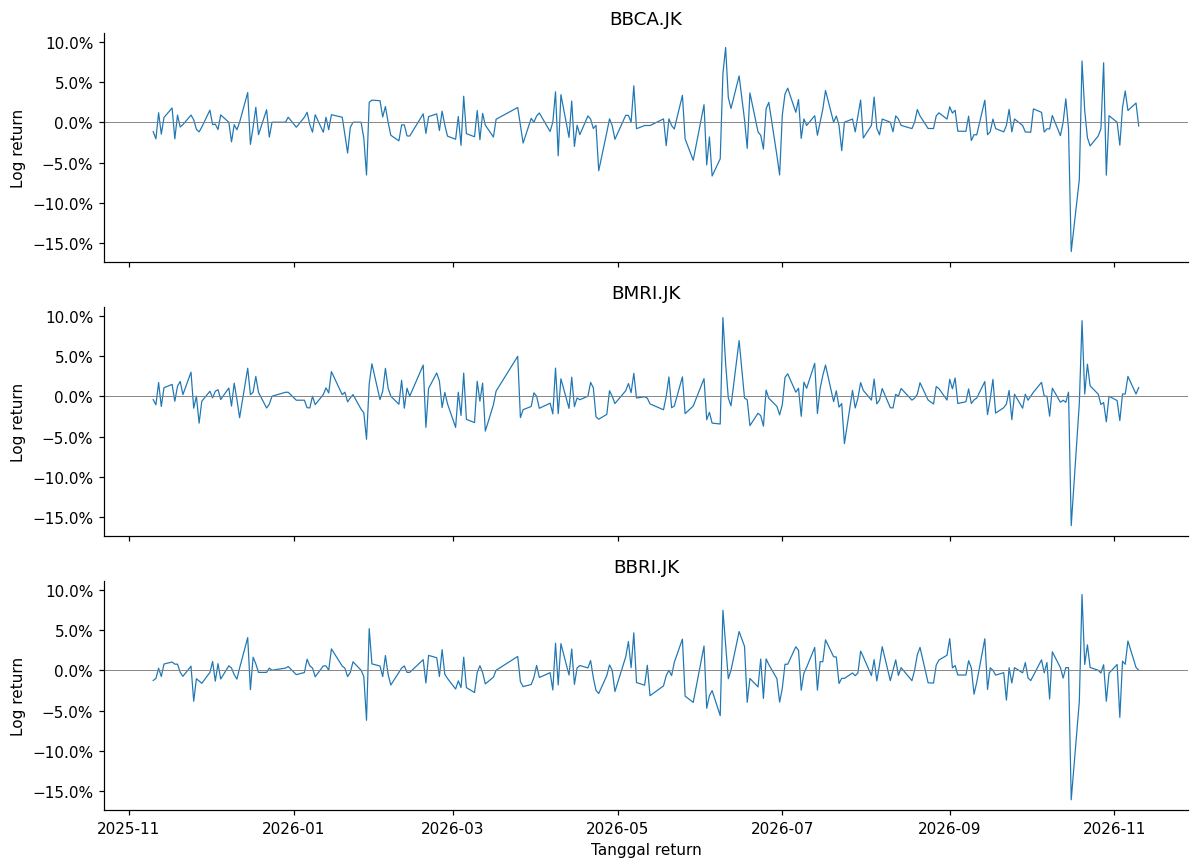

**Gambar 1.** Log return harian ketiga saham tanpa penyaringan; panel menggunakan skala vertikal yang sama.

In [3]:
return_grid = np.log(prices / prices.shift(1)).loc[RETURN_START:RETURN_END]
valid_intervals = return_grid.notna().all(axis=1)
returns = return_grid.loc[valid_intervals].copy()
if not np.isfinite(returns.to_numpy()).all() or len(returns) <= WINDOW:
    raise ValueError('Return tidak valid atau belum cukup untuk rolling window yang dipilih.')

interval_audit = pd.DataFrame(index=prices.index)
interval_audit['previous_date'] = prices.index.to_series().shift(1)
interval_audit['calendar_days'] = prices.index.to_series().diff().dt.days
interval_audit = interval_audit.loc[RETURN_START:RETURN_END]
interval_audit['return_valid'] = valid_intervals
interval_audit.to_csv(TABLE_DIR / 'audit_interval.csv', index_label='date')
returns.to_csv(PROCESSED_DIR / 'return_mentah.csv', index_label='date', float_format='%.17g')
quality.to_csv(TABLE_DIR / 'kualitas_harga.csv', index_label='ticker')

display(pd.Series({
    'jumlah_tanggal_harga': len(prices), 'tanggal_return_kandidat': len(return_grid),
    'return_sah': len(returns), 'interval_dikeluarkan': int((~valid_intervals).sum()),
    'tanggal_return_pertama': str(returns.index.min().date()),
    'tanggal_return_terakhir': str(returns.index.max().date()),
    'jumlah_prediksi_rolling': len(returns) - WINDOW,
}, name='hasil_pemeriksaan').to_frame())

fig, axes = plt.subplots(len(TICKERS), 1, figsize=(11, 8), sharex=True, sharey=True)
for ax, ticker in zip(axes, TICKERS):
    ax.plot(return_grid.index, return_grid[ticker], color='tab:blue', linewidth=0.8)
    ax.axhline(0, color='0.5', linewidth=0.6)
    ax.set(title=ticker, ylabel='Log return')
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[-1].set_xlabel('Tanggal return')
fig.tight_layout()
save_figure(fig, 'gambar_1_return.png')
display(Markdown('**Gambar 1.** Log return harian ketiga saham tanpa penyaringan; '
                 'panel menggunakan skala vertikal yang sama.'))


## 2. Diagnosis data

Semua return sah dipertahankan, termasuk nilai ekstrem. Diagnosis sampel penuh bersifat
retrospektif; setiap estimasi rolling hanya memakai 120 return sah sebelumnya.

### Normalitas Lilliefors

$H_0$: return normal dengan parameter yang diestimasi. Tolak jika p-value $<0{,}05$;
p-value pada batas tabel dilaporkan sebagai batas. Tidak menolak normalitas marginal
belum membuktikan normalitas multivariat. Model normal tetap dijalankan sebagai asumsi replikasi.

,perlakuan,ticker,n,D,p_value_table,p_value_tampil,keputusan_5pct,sifat
0,tanpa_filter,BBCA.JK,240,0.106451,0.001,<= 0.001,Tolak H0,diagnosis seluruh return sah
1,tanpa_filter,BMRI.JK,240,0.099541,0.001,<= 0.001,Tolak H0,diagnosis seluruh return sah
2,tanpa_filter,BBRI.JK,240,0.098420,0.001,<= 0.001,Tolak H0,diagnosis seluruh return sah


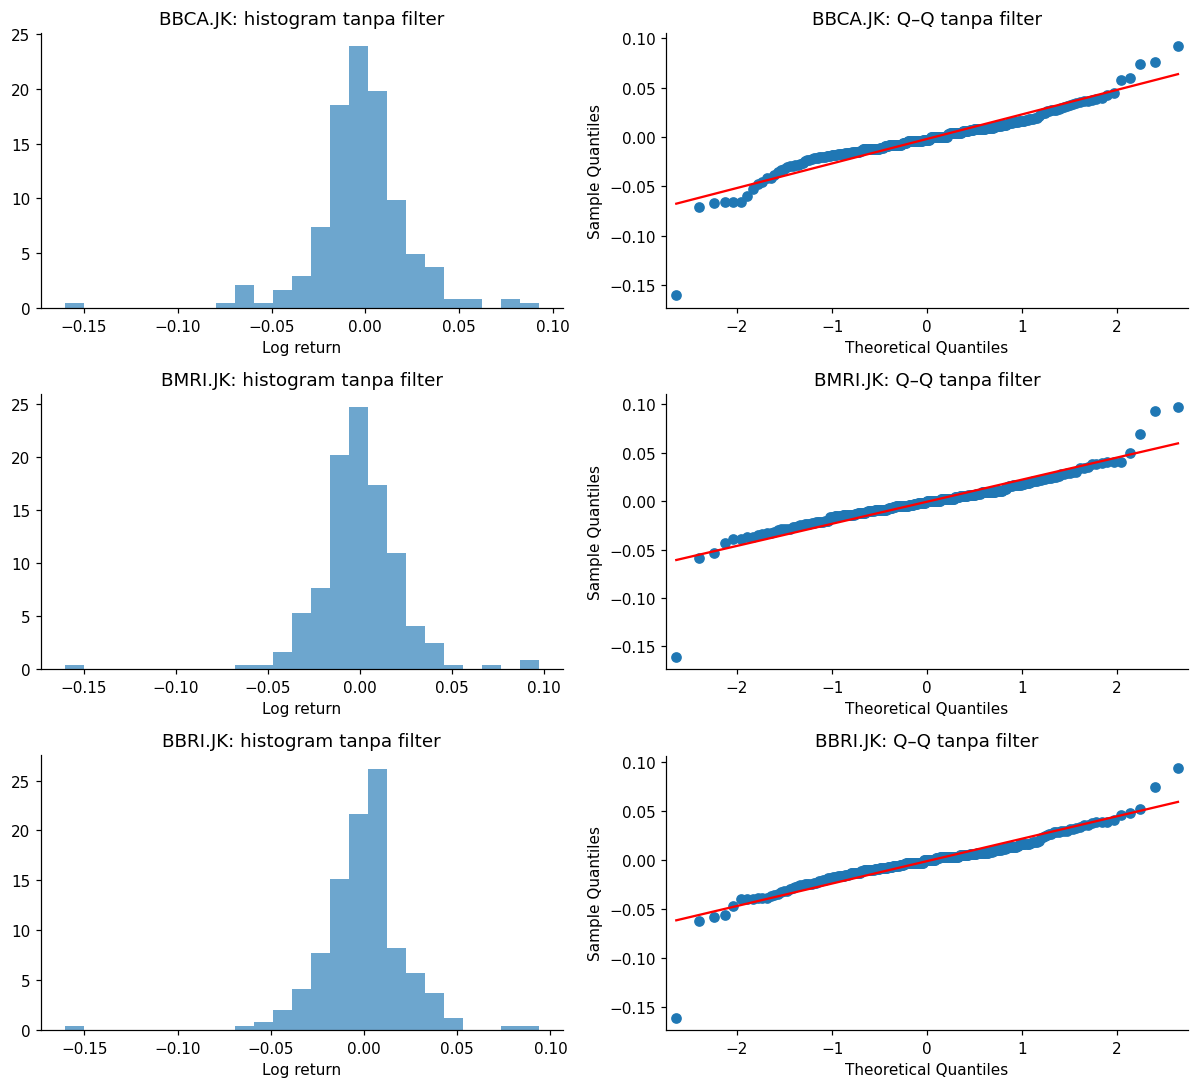

In [4]:
normality_rows = []
for ticker in TICKERS:
    statistic, p_value = lilliefors(returns[ticker], dist='norm', pvalmethod='table')
    p_label = (f'<= {p_value:.3f}' if p_value <= 0.001
               else f'>= {p_value:.3f}' if p_value >= 0.990 else f'{p_value:.6f}')
    normality_rows.append({
        'perlakuan': 'tanpa_filter', 'ticker': ticker, 'n': len(returns),
        'D': statistic, 'p_value_table': p_value, 'p_value_tampil': p_label,
        'keputusan_5pct': 'Tolak H0' if p_value < ALPHA else 'Tidak menolak H0',
        'sifat': 'diagnosis seluruh return sah',
    })
normality_table = pd.DataFrame(normality_rows)
normality_table.to_csv(TABLE_DIR / 'uji_normalitas.csv', index=False)
display(normality_table)

fig, axes = plt.subplots(len(TICKERS), 2, figsize=(11, 10))
for row, ticker in enumerate(TICKERS):
    axes[row, 0].hist(returns[ticker], bins=25, density=True, alpha=0.65)
    axes[row, 0].set(title=f'{ticker}: histogram tanpa filter', xlabel='Log return')
    qqplot(returns[ticker], line='s', ax=axes[row, 1])
    axes[row, 1].set_title(f'{ticker}: Q–Q tanpa filter')
fig.tight_layout()
save_figure(fig, '02_normalitas.png')

### Ketergantungan waktu

ACF return dan kuadrat return merupakan diagnosis grafis hubungan antarwaktu dan
pengelompokan volatilitas, bukan uji formal. Celah `NaN` dipertahankan pada grid tanggal
penyedia. Model normal di sini belum memodelkan dinamika volatilitas.

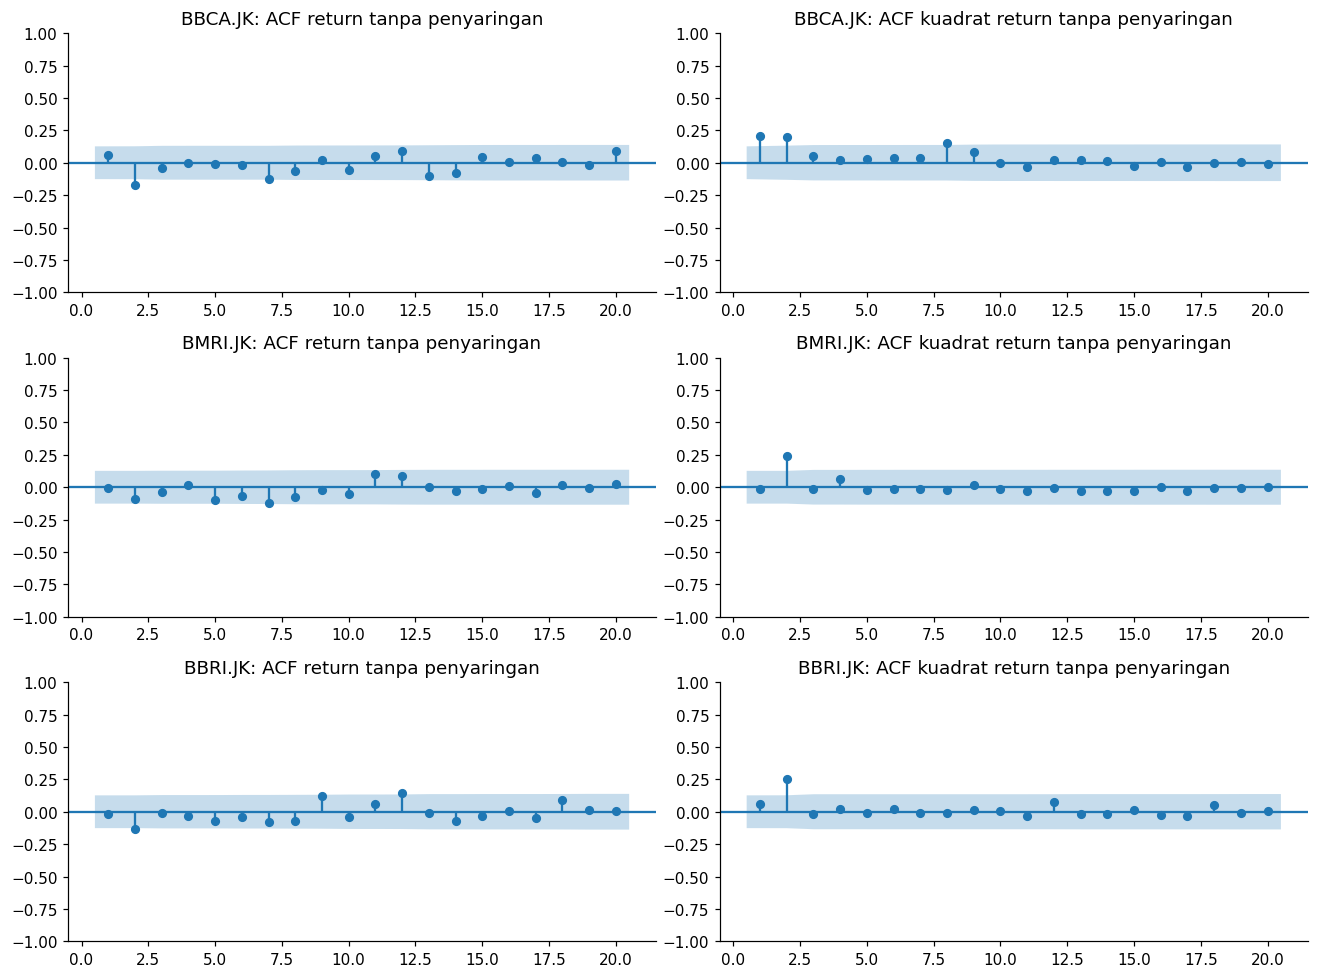

In [5]:
fig, axes = plt.subplots(len(TICKERS), 2, figsize=(12, 9))
lags = min(20, len(return_grid) // 4)
for row, ticker in enumerate(TICKERS):
    series = return_grid[ticker].where(valid_intervals)
    plot_acf(series, lags=lags, zero=False, missing='conservative', ax=axes[row, 0])
    plot_acf(series.pow(2), lags=lags, zero=False, missing='conservative', ax=axes[row, 1])
    axes[row, 0].set_title(f'{ticker}: ACF return tanpa penyaringan')
    axes[row, 1].set_title(f'{ticker}: ACF kuadrat return tanpa penyaringan')
fig.tight_layout()
save_figure(fig, '03_acf.png')

## 3. Parameter aset

Mean, SD, kovarian, dan korelasi memakai seluruh return sah. Kovarian sampel menggunakan
penyebut $N-1$. Matriks harus positif definit untuk GMV dan Cholesky; kegagalan tidak
diatasi dengan regularisasi atau penghapusan aset otomatis.

In [6]:
def estimate_parameters(frame):
    values = frame.to_numpy(dtype=float)
    if len(frame) <= frame.shape[1] or not np.isfinite(values).all():
        raise ValueError('Sampel estimasi tidak cukup atau mengandung nilai tidak valid.')
    mu = values.mean(axis=0)
    covariance = np.cov(values, rowvar=False, ddof=1)
    if not np.allclose(covariance, covariance.T, rtol=1e-12, atol=1e-15):
        raise ValueError('Matriks kovarian tidak simetris.')
    eigenvalues = np.linalg.eigvalsh(covariance)
    if eigenvalues.min() <= 0:
        raise ValueError('Kovarian tidak positif definit; periksa data/model sebelum melanjutkan.')
    return {'mu': mu, 'cov': covariance, 'n': len(frame),
            'min_eigenvalue': float(eigenvalues.min()),
            'condition_number': float(np.linalg.cond(covariance))}


parameters = estimate_parameters(returns)
descriptive = returns.describe().T.assign(
    skewness=returns.skew(), excess_kurtosis=returns.kurt())
descriptive.index.name = 'ticker'
descriptive.insert(0, 'perlakuan', 'tanpa_filter')
descriptive.to_csv(TABLE_DIR / 'statistik_deskriptif.csv')
display(descriptive)
covariance = pd.DataFrame(parameters['cov'], index=TICKERS, columns=TICKERS)
correlation = returns.corr()
covariance.to_csv(TABLE_DIR / 'kovarian_tanpa_filter.csv')
correlation.to_csv(TABLE_DIR / 'korelasi_tanpa_filter.csv')
print('Eigen minimum:', parameters['min_eigenvalue'],
      '| condition number:', parameters['condition_number'])
display(covariance)
display(correlation)

,perlakuan,count,mean,std,min,25%,50%,75%,max,skewness,excess_kurtosis
ticker,,,,,,,,,,,
BBCA.JK,tanpa_filter,240.0,-0.001818,0.024911,-0.160343,-0.012435,-0.003022,0.009126,0.092659,-0.849864,7.871207
BMRI.JK,tanpa_filter,240.0,-0.000484,0.022870,-0.160452,-0.012092,0.000000,0.009858,0.097513,-0.741743,11.574275
BBRI.JK,tanpa_filter,240.0,-0.001021,0.022909,-0.160623,-0.010606,0.000000,0.008017,0.093878,-1.048971,10.625471


Eigen minimum: 9.840032786040898e-05 | condition number: 14.16449273184899


,BBCA.JK,BMRI.JK,BBRI.JK
BBCA.JK,0.000621,0.000401,0.000432
BMRI.JK,0.000401,0.000523,0.000421
BBRI.JK,0.000432,0.000421,0.000525


Ticker,BBCA.JK,BMRI.JK,BBRI.JK
Ticker,,,
BBCA.JK,1.000000,0.703307,0.756563
BMRI.JK,0.703307,1.000000,0.804494
BBRI.JK,0.756563,0.804494,1.000000


### Tabel 1. Statistik return dan normalitas

Mean dan SD dalam persen; variansi dalam return desimal kuadrat. Q-Q dan ACF melengkapi diagnosis.

In [7]:
table_1 = pd.DataFrame({
    'Saham': TICKERS,
    'Mean (%)': returns.mean().reindex(TICKERS).to_numpy() * 100,
    'Variansi (desimal²)': returns.var(ddof=1).reindex(TICKERS).to_numpy(),
    'SD (%)': returns.std(ddof=1).reindex(TICKERS).to_numpy() * 100,
    'Skewness': returns.skew().reindex(TICKERS).to_numpy(),
    'Excess kurtosis': returns.kurt().reindex(TICKERS).to_numpy(),
}).merge(normality_table[['ticker', 'D', 'p_value_tampil']],
         left_on='Saham', right_on='ticker', validate='one_to_one').drop(columns='ticker')
table_1 = table_1.rename(columns={'D': 'Statistik Lilliefors', 'p_value_tampil': 'p-value'})
save_article_table(table_1, 'tabel_1_statistik_normalitas',
                   'Tabel 1. Statistik return harian dan diagnosis normalitas', {
                       'Mean (%)': '{:.4f}', 'Variansi (desimal²)': '{:.6e}',
                       'SD (%)': '{:.4f}', 'Skewness': '{:.4f}',
                       'Excess kurtosis': '{:.4f}', 'Statistik Lilliefors': '{:.4f}',
                   })

Saham,Mean (%),Variansi (desimal²),SD (%),Skewness,Excess kurtosis,Statistik Lilliefors,p-value
BBCA.JK,-0.1818,6.205771e-04,2.4911,-0.8499,7.8712,0.1065,<= 0.001
BMRI.JK,-0.0484,5.230290e-04,2.2870,-0.7417,11.5743,0.0995,<= 0.001
BBRI.JK,-0.1021,5.248322e-04,2.2909,-1.0490,10.6255,0.0984,<= 0.001


## 4. Tiga skema pembobotan

$$w_{GMV}=\frac{\hat\Sigma^{-1}\mathbf1}{\mathbf1'\hat\Sigma^{-1}\mathbf1},
\qquad w_{rata,i}=1/3,\qquad w_{manual}=(0.5,0.3,0.2)'.$$

Mean portofolio $\mu_p=w'\hat\mu$, variansi $w'\hat\Sigma w$, dan
SD $\sigma_p=\sqrt{w'\hat\Sigma w}$ memakai satuan harian. GMV dapat menghasilkan
bobot negatif; eksposur bruto adalah $\sum_i|w_i|$. Bobot manual dipetakan menurut
nama saham agar urutan kolom tidak menukar alokasi. Bobot tidak dinormalisasi diam-diam.

Skema,Bobot BBCA.JK (%),Bobot BMRI.JK (%),Bobot BBRI.JK (%),Mean (%/hari),SD (%/hari),Variansi (desimal²/hari),Eksposur bruto
GMV,22.0831,42.6519,35.265,-0.0967725,2.14524,0.000460207,1
Sama rata,33.3333,33.3333,33.3333,-0.110741,2.15416,0.000464039,1
Manual 50/30/20,50,30,20,-0.125814,2.19169,0.00048035,1


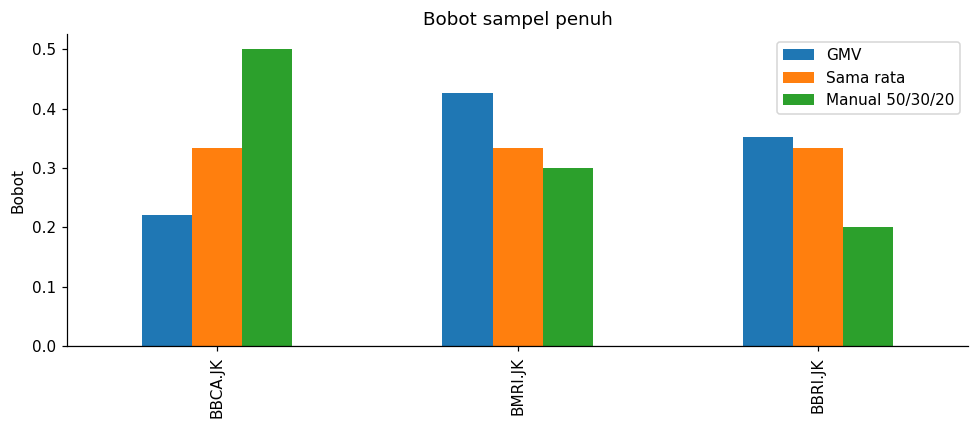

In [8]:
def fit_portfolio(frame, scheme):
    model = estimate_parameters(frame)
    if scheme == 'GMV':
        solution = np.linalg.solve(model['cov'], np.ones(frame.shape[1]))
        weights = solution / solution.sum()
    elif scheme == 'Sama rata':
        weights = np.full(frame.shape[1], 1 / frame.shape[1])
    elif scheme == 'Manual 50/30/20':
        if set(frame.columns) != set(MANUAL_WEIGHTS):
            raise ValueError('Saham bobot manual tidak sesuai dengan kolom data.')
        weights = np.array([MANUAL_WEIGHTS[ticker] for ticker in frame.columns], dtype=float)
        if (weights < 0).any():
            raise ValueError('Skenario manual ini mensyaratkan bobot nonnegatif.')
    else:
        raise ValueError(f'Skema tidak dikenal: {scheme}')
    if not np.isfinite(weights).all() or not np.isclose(weights.sum(), 1, rtol=0, atol=1e-10):
        raise ValueError('Bobot harus finite dan berjumlah satu.')
    model.update({
        'weights': weights, 'chol': np.linalg.cholesky(model['cov']),
        'mu_p': float(weights @ model['mu']),
        'sigma_p': float(np.sqrt(weights @ model['cov'] @ weights)),
    })
    return model


models = {scheme: fit_portfolio(returns, scheme) for scheme in SCHEMES}
weights_table = pd.DataFrame({scheme: model['weights'] for scheme, model in models.items()}, index=TICKERS)
weights_table.to_csv(TABLE_DIR / 'bobot_tiga_skema.csv', index_label='ticker')
portfolio_table = pd.DataFrame([
    {'Skema': scheme, **{f'Bobot {ticker} (%)': weight * 100 for ticker, weight in zip(TICKERS, model['weights'])},
     'Mean (%/hari)': model['mu_p'] * 100, 'SD (%/hari)': model['sigma_p'] * 100,
     'Variansi (desimal²/hari)': model['sigma_p'] ** 2,
     'Eksposur bruto': float(np.abs(model['weights']).sum())}
    for scheme, model in models.items()
])
save_article_table(portfolio_table, 'tabel_2_portofolio', 'Tabel 2. Bobot dan karakteristik tiga portofolio',
                   {column: '{:.6g}' for column in portfolio_table.columns if column != 'Skema'})
fig, ax = plt.subplots(figsize=(9, 4))
weights_table.plot.bar(ax=ax)
ax.axhline(0, color='black', linewidth=0.7)
ax.set(ylabel='Bobot', title='Bobot sampel penuh')
fig.tight_layout()
save_figure(fig, 'bobot_tiga_skema.png')

### Normalitas return historis portofolio

Setelah bobot ditentukan, bentuk satu return portofolio untuk setiap tanggal:

$$\tilde r_{p,t}=\sum_{i=1}^{3}w_i r_{i,t}.$$

Rumus ini mengikuti pendekatan linear gabungan log return aset yang digunakan
pada perhitungan loss notebook, bukan log return portofolio yang dihitung secara eksak.
Bobot sampel penuh masing-masing skema dipakai tetap pada seluruh tanggal diagnosis.
Karena bobot GMV diestimasi dari sampel yang sama, hasilnya bersifat retrospektif;
ini bukan pengujian kinerja di luar sampel atau diagnosis bobot rolling.

Lilliefors diterapkan terpisah pada deret return historis portofolio GMV, sama rata,
dan manual 50/30/20, dengan seluruh return sah tetap disertakan. Yang diuji adalah
return gabungan historis, bukan bobot atau keluaran simulasi normal.
$H_0$: return portofolio berasal dari distribusi normal dengan parameter yang
diestimasi; tolak jika p-value $<0{,}05$. Nilai pada batas tabel ditampilkan sebagai
batas. Tidak menolak $H_0$ belum membuktikan normalitas. P-value mengacu pada asumsi
sampel independen dan identik; ketergantungan waktu dapat memengaruhi interpretasinya.
Uji per saham tetap menjadi diagnosis tambahan dan tidak menggantikan uji portofolio.


Skema,n,Mean (%/hari),SD (%/hari),Statistik Lilliefors,p-value,Keputusan (5%)
GMV,240,-0.0968,2.1452,0.097703,<= 0.001,Tolak H0
Sama rata,240,-0.1107,2.1542,0.100040,<= 0.001,Tolak H0
Manual 50/30/20,240,-0.1258,2.1917,0.095736,<= 0.001,Tolak H0


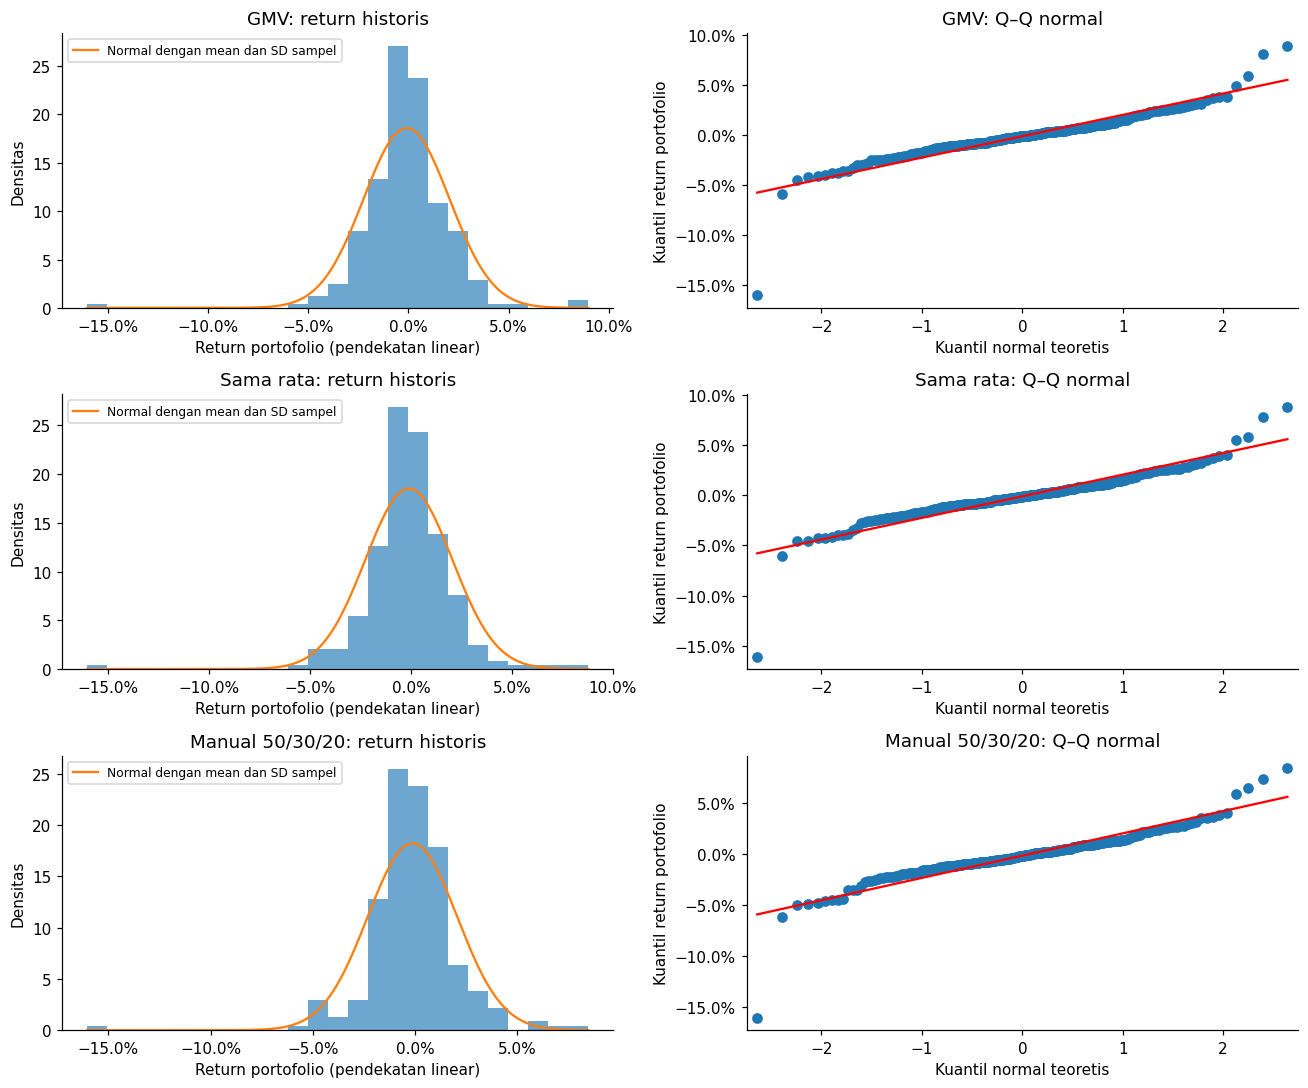

In [9]:
portfolio_returns = pd.DataFrame({
    scheme: returns.to_numpy() @ model['weights']
    for scheme, model in models.items()
}, index=returns.index)
portfolio_returns.to_csv(PROCESSED_DIR / 'return_portofolio.csv',
                         index_label='date', float_format='%.17g')

portfolio_normality_rows = []
for scheme in SCHEMES:
    series = portfolio_returns[scheme]
    statistic, p_value = lilliefors(series, dist='norm', pvalmethod='table')
    p_label = (f'<= {p_value:.3f}' if p_value <= 0.001
               else f'>= {p_value:.3f}' if p_value >= 0.990 else f'{p_value:.6f}')
    portfolio_normality_rows.append({
        'skema': scheme, 'n': len(series), 'mean': series.mean(),
        'sd': series.std(ddof=1), 'D': statistic, 'p_value_table': p_value,
        'p_value_tampil': p_label,
        'keputusan_5pct': 'Tolak H0' if p_value < ALPHA else 'Tidak menolak H0',
    })
portfolio_normality_table = pd.DataFrame(portfolio_normality_rows)
portfolio_normality_table.to_csv(TABLE_DIR / 'uji_normalitas_portofolio.csv',
                                  index=False, float_format='%.17g')

portfolio_normality_display = portfolio_normality_table.drop(columns='p_value_table').copy()
portfolio_normality_display[['mean', 'sd']] *= 100
portfolio_normality_display.columns = [
    'Skema', 'n', 'Mean (%/hari)', 'SD (%/hari)', 'Statistik Lilliefors',
    'p-value', 'Keputusan (5%)',
]
save_article_table(portfolio_normality_display, 'tabel_normalitas_portofolio',
                   'Diagnosis normalitas return historis tiga portofolio', {
                       'n': '{:.0f}', 'Mean (%/hari)': '{:.4f}',
                       'SD (%/hari)': '{:.4f}', 'Statistik Lilliefors': '{:.6f}',
                   })

fig, axes = plt.subplots(len(SCHEMES), 2, figsize=(12, 10), squeeze=False)
for row, scheme in enumerate(SCHEMES):
    series = portfolio_returns[scheme]
    axes[row, 0].hist(series, bins=25, density=True, alpha=0.65)
    grid = np.linspace(series.min(), series.max(), 300)
    axes[row, 0].plot(grid, norm.pdf(grid, series.mean(), series.std(ddof=1)),
                      label='Normal dengan mean dan SD sampel')
    axes[row, 0].set(title=f'{scheme}: return historis',
                     xlabel='Return portofolio (pendekatan linear)', ylabel='Densitas')
    axes[row, 0].xaxis.set_major_formatter(PercentFormatter(1))
    axes[row, 0].legend(fontsize=8)
    qqplot(series, line='s', ax=axes[row, 1])
    axes[row, 1].set(title=f'{scheme}: Q–Q normal',
                     xlabel='Kuantil normal teoretis', ylabel='Kuantil return portofolio')
    axes[row, 1].yaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
save_figure(fig, 'normalitas_portofolio.png')


### Interpretasi normalitas portofolio

Baca keputusan setiap skema secara terpisah. Penolakan $H_0$ menunjukkan bukti
ketidaksesuaian distribusi return historis portofolio dengan model normal;
tidak menolak $H_0$ berarti bukti penolakan belum cukup pada taraf 5%.
Histogram dan Q–Q plot membantu melihat kemencengan serta penyimpangan di ekor,
yang relevan bagi VaR/CVaR. Normalitas portofolio tertentu tidak membuktikan
normalitas multivariat seluruh return saham.

Model normal tetap dijalankan sebagai asumsi replikasi, apa pun hasil diagnosis.
Tidak ada return ekstrem yang dihapus untuk memperoleh normalitas. Kedekatan
Monte Carlo dengan rumus normal analitik memeriksa konsistensi numerik model;
backtesting tetap diperlukan untuk menilai cakupan VaR pada data aktual.


## 5. Simulasi berkorelasi

$$r^{(m)}=\hat\mu+Lz^{(m)},\quad LL'=\hat\Sigma,\quad z^{(m)}\sim N(0,I).$$

Implementasi baris skenario: `Z @ L.T + mu`. Setiap skenario adalah kemungkinan satu hari;
Cholesky mempertahankan kovarian antarsaham. `SeedSequence([SEED, tahap, 0, kunci])`
memakai tahap 2 untuk sampel penuh, 3 untuk konvergensi (kunci jumlah skenario),
dan 4 untuk rolling (kunci `YYYYMMDD`). Child seed berbeda per pengulangan, tetapi
identik antarskema agar setiap bobot diuji pada skenario aset yang sama.

In [10]:
def make_seed(stage, key=0):
    return np.random.SeedSequence([SEED, stage, 0, key])

def simulate_asset_returns(model, n_scenarios, rng):
    z = rng.standard_normal((n_scenarios, len(model['mu'])))
    return z @ model['chol'].T + model['mu']

## 6. Loss, VaR, dan CVaR

$$\tilde r_p=w'r,\quad\ell=-\tilde r_p,\qquad \operatorname{VaR}_c=q_c(\ell).$$

Loss positif berarti rugi. Agregasi berbobot log return merupakan pendekatan linear
harian; definisi yang sama dipakai untuk MC, normal, historis, dan loss aktual.
Kuantil memakai interpolasi linear tipe 7. VaR bukan kerugian maksimum mutlak;
nilai negatif tidak dipaksa positif.

Untuk model kontinu, $\operatorname{CVaR}_c=E[\ell\mid\ell\ge\operatorname{VaR}_c]$.
Estimator sampel mengambil massa ekor tepat $h=N(1-c)$: jumlahkan $\lfloor h\rfloor$
loss terbesar dan pecahan loss berikutnya, lalu bagi $h$. Cara ini menangani ties
dan massa pecahan. Pada 10.000 skenario, massa ekor 95% adalah 500 skenario.
Kerugian aktual dapat melampaui VaR maupun CVaR.

In [11]:
def risk_from_losses(losses, levels=LEVELS):
    losses = np.asarray(losses, dtype=float)
    if losses.ndim != 1 or losses.size < 2 or not np.isfinite(losses).all():
        raise ValueError('Loss harus berupa vektor finite dengan minimal dua observasi.')
    quantiles = np.quantile(losses, levels, method='linear')
    descending = np.sort(losses)[::-1]
    cumulative = np.concatenate(([0.0], np.cumsum(descending)))
    rows = []
    for confidence, var in zip(levels, quantiles):
        h = len(losses) * (1 - confidence)
        if not 0 < h < len(losses):
            raise ValueError('Tingkat kepercayaan harus berada di antara 0 dan 1.')
        if np.isclose(h, round(h), atol=1e-10, rtol=0):
            h = float(round(h))
        j = int(np.floor(h))
        cvar = (cumulative[j] + (h - j) * descending[j]) / h
        rows.append({'confidence': float(confidence), 'var': float(var), 'cvar': float(cvar),
                     'tail_count': int(np.count_nonzero(losses >= var)), 'tail_mass_n': h})
    return pd.DataFrame(rows)

## 7. Estimasi Monte Carlo

Parameter dan bobot tetap dalam satu sampel estimasi. Setiap pengulangan memakai skenario
baru; VaR/CVaR dihitung per pengulangan lalu dirata-ratakan. Menggabungkan semua skenario
sebelum mengambil satu kuantil merupakan estimator berbeda. Skenario tidak disimpan seluruhnya.

In [12]:
def run_mc(model, n_scenarios, n_repeats, seed_sequence):
    if n_scenarios < 2 or n_repeats < 2:
        raise ValueError('MC memerlukan minimal dua skenario dan dua pengulangan untuk menghitung SD/SE.')
    repetitions = []
    for repeat, child_seed in enumerate(seed_sequence.spawn(n_repeats), start=1):
        asset_returns = simulate_asset_returns(model, n_scenarios, np.random.default_rng(child_seed))
        losses = -(asset_returns @ model['weights'])
        result = risk_from_losses(losses)
        result.insert(0, 'repeat', repeat)
        repetitions.append(result)
    repetitions = pd.concat(repetitions, ignore_index=True)
    summary = repetitions.groupby('confidence')[['var', 'cvar']].agg(['mean', 'std'])
    summary.columns = ['_'.join(parts) for parts in summary.columns]
    summary['var_se'] = summary['var_std'] / np.sqrt(n_repeats)
    summary['cvar_se'] = summary['cvar_std'] / np.sqrt(n_repeats)
    summary = summary.reset_index()
    if (summary['cvar_mean'] < summary['var_mean'] - 1e-12).any():
        raise ArithmeticError('CVaR lebih kecil dari VaR; periksa perhitungan.')
    if (np.diff(summary['var_mean']) < -1e-12).any() or (np.diff(summary['cvar_mean']) < -1e-12).any():
        raise ArithmeticError('Urutan risiko antar level tidak konsisten.')
    return repetitions, summary

### SD dan SE simulasi

$$\bar\theta=K^{-1}\sum_k\hat\theta_k,\quad
s_{MC}=\sqrt{\frac{\sum_k(\hat\theta_k-\bar\theta)^2}{K-1}},\quad
SE_{MC}=s_{MC}/\sqrt K.$$

SD mengukur variasi antarpengulangan; SE mengukur galat rata-rata simulasi bersyarat
pada parameter estimasi. Keduanya belum mencakup ketidakpastian parameter atau kesalahan
model. Tabel tampilan mengubah risiko ke persen dan SD/SE ke pp; CSV rinci tetap desimal.

In [13]:
full_repetition_rows, full_summary_rows = [], []
for scheme, model in models.items():
    repetitions, summary = run_mc(model, M, K, make_seed(2))
    full_repetition_rows.append(repetitions.assign(skema=scheme))
    full_summary_rows.append(summary.assign(skema=scheme, M=M, K=K, n_estimasi=model['n']))
full_repetitions = pd.concat(full_repetition_rows, ignore_index=True)
full_summary = pd.concat(full_summary_rows, ignore_index=True)
full_repetitions.to_csv(TABLE_DIR / 'mc_pengulangan_sampel_penuh.csv', index=False)
full_summary.to_csv(TABLE_DIR / 'mc_ringkasan_sampel_penuh.csv', index=False)
table_3 = full_summary[['skema', 'confidence', 'var_mean', 'cvar_mean', 'var_std', 'cvar_std', 'var_se', 'cvar_se']].copy()
table_3.columns = ['Skema', 'Level (%)', 'VaR (%)', 'CVaR (%)', 'SD VaR (pp)', 'SD CVaR (pp)', 'SE VaR (pp)', 'SE CVaR (pp)']
table_3.iloc[:, 1:] *= 100
save_article_table(table_3, 'tabel_3_risiko_mc', 'Tabel 3. Risiko Monte Carlo satu hari',
                   {column: '{:.6f}' for column in table_3.columns if column != 'Skema'})

Skema,Level (%),VaR (%),CVaR (%),SD VaR (pp),SD CVaR (pp),SE VaR (pp),SE CVaR (pp)
GMV,95.000000,3.630941,4.526269,0.047044,0.051955,0.004704,0.005196
Sama rata,95.000000,3.657280,4.558003,0.046579,0.051757,0.004658,0.005176
Manual 50/30/20,95.000000,3.734148,4.649954,0.048825,0.052800,0.004882,0.005280


## 8. Verifikasi Monte Carlo dengan rumus normal analitik

$$\mu_p=w'\hat\mu,\quad\sigma_p=\sqrt{w'\hat\Sigma w},$$
$$\operatorname{VaR}_c=-\mu_p+\sigma_p\Phi^{-1}(c),\qquad
\operatorname{CVaR}_c=-\mu_p+\sigma_p\frac{\phi(\Phi^{-1}(c))}{1-c}.$$

Solusi normal analitik memeriksa MC pada model yang sama. Bias kuantil/ekor pada
$M$ terbatas tetap ada, sehingga selisih/SE bukan syarat kelulusan universal.
Hasil analitik hanya menjadi acuan verifikasi numerik, bukan metode estimasi
yang dibandingkan atau diikutkan dalam backtesting.

In [14]:
def normal_risk(model, levels=LEVELS):
    z = norm.ppf(levels)
    return pd.DataFrame({
        'confidence': levels,
        'var_normal': -model['mu_p'] + model['sigma_p'] * z,
        'cvar_normal': -model['mu_p'] + model['sigma_p'] * norm.pdf(z) / (1 - levels),
    })

In [15]:
comparison_rows = []
for scheme, model in models.items():
    comparison = full_summary.loc[full_summary['skema'] == scheme].merge(
        normal_risk(model), on='confidence', validate='one_to_one')
    for metric in ['var', 'cvar']:
        comparison[f'{metric}_difference'] = comparison[f'{metric}_mean'] - comparison[f'{metric}_normal']
        comparison[f'{metric}_difference_over_se'] = comparison[f'{metric}_difference'] / comparison[f'{metric}_se']
    comparison_rows.append(comparison)
comparison_table = pd.concat(comparison_rows, ignore_index=True)
comparison_table.to_csv(TABLE_DIR / 'verifikasi_analitik.csv', index=False)
table_4 = comparison_table[['skema', 'confidence', 'var_mean', 'var_normal',
                           'cvar_mean', 'cvar_normal', 'var_difference_over_se', 'cvar_difference_over_se']].copy()
table_4.columns = ['Skema', 'Level (%)', 'VaR MC (%)', 'VaR analitik (%)',
                   'CVaR MC (%)', 'CVaR analitik (%)', 'Selisih VaR / SE', 'Selisih CVaR / SE']
table_4.iloc[:, 1:6] *= 100
save_article_table(table_4, 'tabel_4_pembanding', 'Tabel 4. Verifikasi numerik Monte Carlo terhadap rumus normal analitik',
                   {column: '{:.6f}' for column in table_4.columns if column != 'Skema'})

Skema,Level (%),VaR MC (%),VaR analitik (%),CVaR MC (%),CVaR analitik (%),Selisih VaR / SE,Selisih CVaR / SE
GMV,95.000000,3.630941,3.625386,4.526269,4.521796,1.180858,0.861004
Sama rata,95.000000,3.657280,3.654013,4.558003,4.554147,0.701414,0.745001
Manual 50/30/20,95.000000,3.734148,3.730823,4.649954,4.646640,0.681131,0.627575


## 9. Konvergensi

Uji 1.000, 10.000, dan 100.000 skenario, masing-masing 100 pengulangan per skema,
dengan aliran acak terpisah dari estimasi utama. Grafik menunjukkan MC minus analitik
beserta $\pm2SE_{MC}$, bukan interval seluruh ketidakpastian risiko pasar.
Menambah skenario tidak menambah hari pasar atau memperbaiki asumsi model.

Konvergensi selesai: GMV


Konvergensi selesai: Sama rata


Konvergensi selesai: Manual 50/30/20


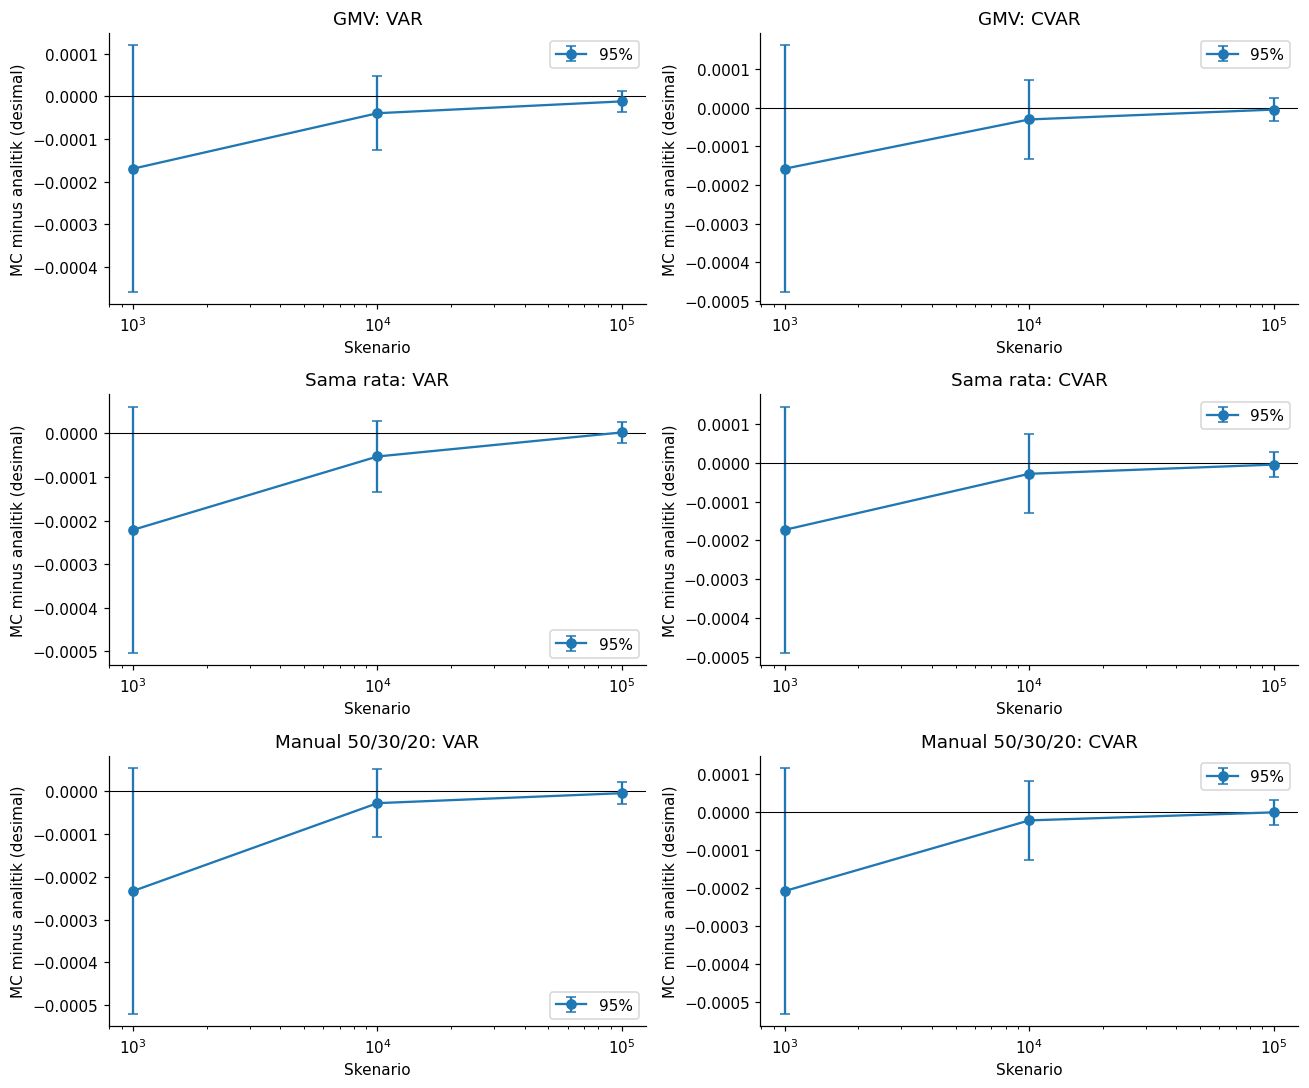

In [16]:
convergence_table = None
if RUN_CONVERGENCE:
    convergence_rows = []
    for scheme, model in models.items():
        for n_scenarios in CONVERGENCE_M:
            repetitions, summary = run_mc(model, n_scenarios, K, make_seed(3, n_scenarios))
            repetitions.assign(skema=scheme, M=n_scenarios).to_csv(
                TABLE_DIR / f'konvergensi_pengulangan_{SCHEMES.index(scheme)}_{n_scenarios}.csv', index=False)
            summary = summary.merge(normal_risk(model), on='confidence', validate='one_to_one')
            convergence_rows.append(summary.assign(skema=scheme, M=n_scenarios, K=K))
        print(f'Konvergensi selesai: {scheme}')
    convergence_table = pd.concat(convergence_rows, ignore_index=True)
    convergence_table.to_csv(TABLE_DIR / 'konvergensi.csv', index=False)
    fig, axes = plt.subplots(len(SCHEMES), 2, figsize=(12, 10), squeeze=False)
    for row, scheme in enumerate(SCHEMES):
        for ax, metric in zip(axes[row], ['var', 'cvar']):
            for confidence in LEVELS:
                group = convergence_table.loc[(convergence_table['skema'] == scheme) &
                    np.isclose(convergence_table['confidence'], confidence)].sort_values('M')
                ax.errorbar(group['M'], group[f'{metric}_mean'] - group[f'{metric}_normal'],
                            yerr=2 * group[f'{metric}_se'], marker='o', capsize=3, label=f'{confidence:.0%}')
            ax.axhline(0, color='black', linewidth=0.7)
            ax.set(xscale='log', title=f'{scheme}: {metric.upper()}', xlabel='Skenario', ylabel='MC minus analitik (desimal)')
            ax.legend()
    fig.tight_layout()
    save_figure(fig, 'konvergensi_tiga_skema.png')
else:
    print('Konvergensi belum dijalankan.')

## 10. Backtesting VaR

Pelanggaran terjadi saat `loss > VaR`. Kupiec membandingkan frekuensi pelanggaran
dengan $p=1-c$ menggunakan LR dan pendekatan $\chi^2_1$. `xlogy` menangani
$0\log0$, termasuk nol/seluruh observasi melanggar. Hasil dalam sampel hanya
menggambarkan kecocokan pada data pembentuk parameter, bukan prediksi.

In [17]:
def kupiec_test(n, x, confidence, alpha=ALPHA):
    if n <= 0 or not 0 <= x <= n or not 0 < confidence < 1:
        raise ValueError('Input Kupiec tidak valid.')
    p = 1 - confidence
    empirical_p = x / n
    log_null = xlogy(n - x, 1 - p) + xlogy(x, p)
    log_alternative = xlogy(n - x, 1 - empirical_p) + xlogy(x, empirical_p)
    lr = max(0.0, float(2 * (log_alternative - log_null)))
    p_value = float(chi2.sf(lr, df=1))
    return {'n': int(n), 'x': int(x), 'expected_x': n * p, 'failure_rate': empirical_p,
            'nominal_failure_rate': p, 'LR_POF': lr, 'p_value': p_value,
            'keputusan_5pct': 'Tolak H0' if p_value < alpha else 'Tidak menolak H0'}


in_sample_rows = []
for scheme, model in models.items():
    actual_losses = -(returns.to_numpy() @ model['weights'])
    for _, risk in full_summary.loc[full_summary['skema'] == scheme].iterrows():
        result = kupiec_test(len(actual_losses), int(np.sum(actual_losses > risk['var_mean'])),
                             risk['confidence'])
        in_sample_rows.append({'skema': scheme, 'method': 'Monte Carlo',
                               'confidence': risk['confidence'],
                               'evaluasi': 'dalam_sampel', **result})
in_sample_table = pd.DataFrame(in_sample_rows)
in_sample_table.to_csv(TABLE_DIR / 'kupiec_dalam_sampel.csv', index=False)

### Rolling 120 observasi sebelum tanggal uji

Parameter normal diperbarui pada setiap jendela untuk ketiga skema. Hanya GMV
yang mengestimasi ulang bobot. VaR diprediksi dengan Monte Carlo pada setiap
skema; loss aktual dihitung memakai bobot prediksi skema tersebut. Pelanggaran memakai
`loss > VaR`, termasuk pada tanggal dengan return ekstrem yang sah.

Jumlah tanggal uji $T-120$. Checkpoint dipisah per skema dan fingerprint data,
konfigurasi, versi pustaka, serta sumber fungsi. Eksekusi terputus dapat dilanjutkan
dengan `RESUME_ROLLING=True`; cache tidak sesuai menghentikan proses.

In [18]:
def predict_one_day(train, realized, date, scheme):
    model = fit_portfolio(train, scheme)
    date_key = int(date.strftime('%Y%m%d'))
    repetitions, summary = run_mc(model, M, K, make_seed(4, date_key))
    realized_loss = float(-(realized.to_numpy() @ model['weights']))
    weight_record = {f'w_{ticker}': float(weight) for ticker, weight in zip(TICKERS, model['weights'])}
    common = {'date': date.strftime('%Y-%m-%d'), 'skema': scheme,
              'train_start': train.index.min().strftime('%Y-%m-%d'),
              'train_end': train.index.max().strftime('%Y-%m-%d'),
              'n_window': len(train), 'n_fit': len(train),
              'n_removed': 0, 'loss': realized_loss,
              'gross_exposure': float(np.abs(model['weights']).sum()), **weight_record}
    predictions = []
    for position, confidence in enumerate(LEVELS):
        mc = summary.iloc[position]
        predictions.append({**common, 'confidence': float(confidence), 'method': 'Monte Carlo',
                            'var': float(mc['var_mean']), 'cvar': float(mc['cvar_mean']),
                            'mc_var_se': float(mc['var_se']), 'mc_cvar_se': float(mc['cvar_se']),
                            'breach': int(realized_loss > mc['var_mean'])})
    return {'predictions': predictions, 'repetitions': repetitions.to_dict(orient='records'),
            'parameters': {'mu': model['mu'].tolist(), 'cov': model['cov'].tolist(),
                           'weights': model['weights'].tolist(),
                           'condition_number': model['condition_number']}}

In [19]:
def rolling_backtest(data, checkpoint_folder, run_id, scheme):
    prediction_rows, repetition_rows = [], []
    n_dates = len(data) - WINDOW
    started = time.perf_counter()
    for position in range(WINDOW, len(data)):
        date = data.index[position]
        train = data.iloc[position - WINDOW:position]
        checkpoint = checkpoint_folder / f'{date:%Y%m%d}.json'
        if checkpoint.exists() and RESUME_ROLLING:
            payload = json.loads(checkpoint.read_text(encoding='utf-8'))
            if (payload['run_id'] != run_id or payload['date'] != date.strftime('%Y-%m-%d')
                    or payload['skema'] != scheme):
                raise ValueError(f'Identitas checkpoint tidak cocok: {checkpoint.name}')
            result = payload['result']
            if len(result['predictions']) != len(LEVELS) or len(result['repetitions']) != K * len(LEVELS):
                raise ValueError(f'Checkpoint tidak lengkap: {checkpoint.name}')
        else:
            result = predict_one_day(train, data.iloc[position], date, scheme)
            payload = {'run_id': run_id, 'date': date.strftime('%Y-%m-%d'),
                       'skema': scheme, 'result': result}
            temporary = checkpoint.with_suffix('.tmp')
            temporary.write_text(json.dumps(payload, allow_nan=False), encoding='utf-8')
            temporary.replace(checkpoint)
        prediction_rows.extend(result['predictions'])
        repetition_rows.extend({**row, 'date': date.strftime('%Y-%m-%d'), 'skema': scheme}
                               for row in result['repetitions'])
        completed = position - WINDOW + 1
        if completed == 1 or completed % 10 == 0 or completed == n_dates:
            elapsed = time.perf_counter() - started
            print(f'{completed}/{n_dates} tanggal selesai | {date:%Y-%m-%d} | {elapsed:.1f} detik')
    predictions = pd.DataFrame(prediction_rows)
    predictions['date'] = pd.to_datetime(predictions['date'])
    repetitions = pd.DataFrame(repetition_rows)
    return predictions, repetitions

In [20]:
rolling_predictions = rolling_repetitions = None
rolling_run_ids = {}
if RUN_ROLLING:
    numerical_functions = [estimate_parameters, fit_portfolio, make_seed, simulate_asset_returns,
                           risk_from_losses, run_mc, predict_one_day, rolling_backtest]
    implementation = '\n'.join(inspect.getsource(function) for function in numerical_functions)
    data_digest = hashlib.sha256(pd.util.hash_pandas_object(returns, index=True).values.tobytes()).hexdigest()
    prediction_frames, repetition_frames = [], []
    for scheme in SCHEMES:
        rolling_config = {'tickers': TICKERS, 'levels': LEVELS.tolist(), 'window': WINDOW,
                          'M': M, 'K': K, 'seed': SEED, 'seed_stream_id': 0,
                          'skema': scheme, 'manual_weights': MANUAL_WEIGHTS,
                          'method': 'Monte Carlo', 'filter': 'none', 'quantile': 'linear_type7',
                          'loss': 'negative_weighted_log_return', 'versions': VERSIONS}
        run_spec = {'config': rolling_config, 'data_sha256': data_digest,
                    'implementation_sha256': hashlib.sha256(implementation.encode()).hexdigest()}
        run_id = hashlib.sha256(json.dumps(run_spec, sort_keys=True).encode()).hexdigest()[:20]
        rolling_run_ids[scheme] = run_id
        run_folder = CHECKPOINT_DIR / run_id
        run_folder.mkdir(exist_ok=True)
        (run_folder / 'run_spec.json').write_text(json.dumps(run_spec, indent=2), encoding='utf-8')
        print(f'{scheme}: {len(returns) - WINDOW} tanggal uji, run {run_id}')
        predictions, repetitions = rolling_backtest(returns, run_folder, run_id, scheme)
        prediction_frames.append(predictions)
        repetition_frames.append(repetitions)
    rolling_predictions = pd.concat(prediction_frames, ignore_index=True)
    rolling_repetitions = pd.concat(repetition_frames, ignore_index=True)
    rolling_predictions.to_csv(TABLE_DIR / 'rolling_prediksi.csv', index=False)
    rolling_repetitions.to_csv(TABLE_DIR / 'rolling_mc_pengulangan.csv', index=False)
    rolling_weights = rolling_predictions.drop_duplicates(['skema', 'date'])[
        ['skema', 'date', 'train_start', 'train_end', 'n_window', 'n_fit', 'n_removed', 'gross_exposure']
        + [f'w_{ticker}' for ticker in TICKERS]]
    rolling_weights.to_csv(TABLE_DIR / 'rolling_bobot_estimasi.csv', index=False)
else:
    print('Rolling belum dijalankan; hasil dalam sampel tidak menggantikannya.')

GMV: 120 tanggal uji, run 1a73e930130a31cec90a


1/120 tanggal selesai | 2026-05-19 | 0.3 detik


10/120 tanggal selesai | 2026-06-04 | 3.3 detik


20/120 tanggal selesai | 2026-06-19 | 6.5 detik


30/120 tanggal selesai | 2026-07-03 | 9.4 detik


40/120 tanggal selesai | 2026-07-17 | 12.6 detik


... (30 outputs left out)

90/120 tanggal selesai | 2026-09-29 | 34.5 detik


100/120 tanggal selesai | 2026-10-13 | 39.0 detik


110/120 tanggal selesai | 2026-10-27 | 42.6 detik


120/120 tanggal selesai | 2026-11-10 | 45.9 detik


### Kupiec di luar sampel

Laporkan $n$, pelanggaran $x$, harapan $n(1-c)$, proporsi pelanggaran, LR, dan
p-value. Taraf uji 5%. Pada 95% dan 120 tanggal uji, harapan pelanggaran adalah 6;
pendekatan chi-square dan kekuatan pengujian terbatas. Kupiec tidak memvalidasi
CVaR atau independensi pelanggaran. P-value terbesar bukan penentu skema terbaik.

Skema,Metode,Level (%),n,Pelanggaran,Harapan,Pelanggaran (%),LR Kupiec,p-value,Keputusan
GMV,Monte Carlo,95,120,7,6.0,5.8333,0.166907,0.682875,Tidak menolak H0
Manual 50/30/20,Monte Carlo,95,120,8,6.0,6.6667,0.638208,0.42436,Tidak menolak H0
Sama rata,Monte Carlo,95,120,8,6.0,6.6667,0.638208,0.42436,Tidak menolak H0


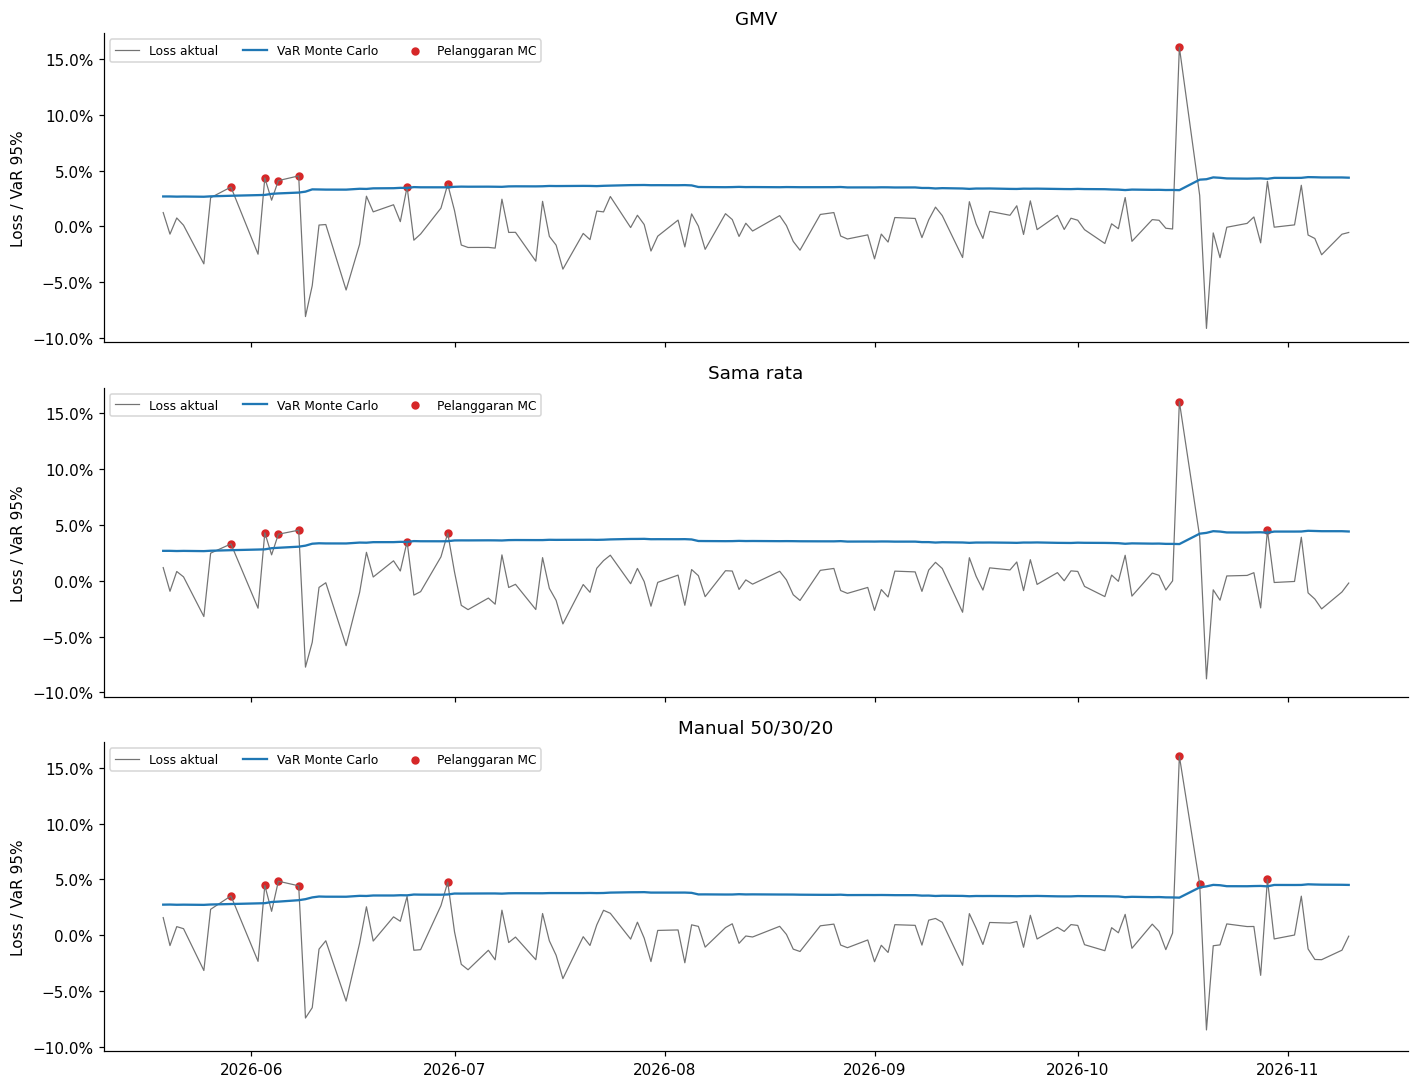

In [21]:
rolling_kupiec = None
if rolling_predictions is not None:
    expected_dates = pd.DatetimeIndex(returns.index[WINDOW:])
    rows = []
    for (scheme, method, confidence), group in rolling_predictions.groupby(['skema', 'method', 'confidence']):
        group = group.sort_values('date')
        if not pd.DatetimeIndex(group['date']).equals(expected_dates):
            raise AssertionError('Tanggal uji Monte Carlo tidak lengkap atau berbeda antarskema.')
        result = kupiec_test(len(group), int(group['breach'].sum()), confidence)
        rows.append({'skema': scheme, 'method': method, 'confidence': confidence,
                     'evaluasi': 'di_luar_sampel', **result})
    rolling_kupiec = pd.DataFrame(rows)
    rolling_kupiec.to_csv(TABLE_DIR / 'kupiec_di_luar_sampel.csv', index=False)
    table_5 = rolling_kupiec[['skema', 'method', 'confidence', 'n', 'x', 'expected_x',
                             'failure_rate', 'LR_POF', 'p_value', 'keputusan_5pct']].copy()
    table_5['confidence'] *= 100
    table_5['failure_rate'] *= 100
    table_5.columns = ['Skema', 'Metode', 'Level (%)', 'n', 'Pelanggaran', 'Harapan',
                       'Pelanggaran (%)', 'LR Kupiec', 'p-value', 'Keputusan']
    save_article_table(table_5, 'tabel_5_backtesting_rolling', 'Tabel 5. Kupiec VaR Monte Carlo di luar sampel',
                       {'Level (%)': '{:.0f}', 'Harapan': '{:.1f}', 'Pelanggaran (%)': '{:.4f}',
                        'LR Kupiec': '{:.6f}', 'p-value': '{:.6g}'})
    fig, axes = plt.subplots(len(SCHEMES), 1, figsize=(13, 10), sharex=True, sharey=True)
    for ax, scheme in zip(axes, SCHEMES):
        subset = rolling_predictions.loc[(rolling_predictions['skema'] == scheme) &
            np.isclose(rolling_predictions['confidence'], 0.95)]
        actual = subset.loc[subset['method'] == 'Monte Carlo'].sort_values('date')
        ax.plot(actual['date'], actual['loss'], color='0.45', linewidth=0.8, label='Loss aktual')
        ax.plot(actual['date'], actual['var'], label='VaR Monte Carlo')
        failures = actual.loc[actual['breach'] == 1]
        ax.scatter(failures['date'], failures['loss'], color='tab:red', s=20, label='Pelanggaran MC')
        ax.set(title=scheme, ylabel='Loss / VaR 95%')
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.legend(fontsize=8, ncol=3)
    fig.tight_layout()
    save_figure(fig, 'rolling_var95_tiga_skema.png')

## 11. Rupiah dan metadata

Risiko rupiah $\approx V_0\times$ risiko desimal, dengan $V_0=\mathrm{Rp}100.000.000$,
mengikuti pendekatan return linear tanpa biaya transaksi. Tabel sampel penuh
bersifat retrospektif; kesimpulan prediksi mengacu pada rolling di luar sampel.

In [22]:
rupiah_table = full_summary[['skema', 'confidence', 'var_mean', 'cvar_mean']].copy()
rupiah_table['VaR_Rp_pendekatan'] = rupiah_table['var_mean'] * V0
rupiah_table['CVaR_Rp_pendekatan'] = rupiah_table['cvar_mean'] * V0
rupiah_table.to_csv(TABLE_DIR / 'ilustrasi_rupiah.csv', index=False)
display(rupiah_table.loc[np.isclose(rupiah_table['confidence'], 0.95)].style.format(
    {'VaR_Rp_pendekatan': 'Rp {:,.0f}', 'CVaR_Rp_pendekatan': 'Rp {:,.0f}'}))
config_record = {
    'source_notebook': 'replikasi_var_cvar_artikel_3_pembobotan.ipynb',
    'estimation_method': 'Monte Carlo', 'analytic_role': 'numerical_verification_only',
    'tickers': TICKERS, 'return_start': RETURN_START, 'return_end': RETURN_END,
    'schemes': SCHEMES, 'manual_weights': MANUAL_WEIGHTS,
    'fixed_weights_policy': 'daily target rebalance, not buy-and-hold',
    'levels': LEVELS.tolist(), 'alpha': ALPHA, 'filter': 'none',
    'M': M, 'K': K, 'seed': SEED, 'window': WINDOW, 'V0': V0,
    'convergence_M': CONVERGENCE_M, 'allow_missing_intervals': ALLOW_MISSING_INTERVALS,
    'loss_definition': 'negative weighted asset log returns; daily linear approximation',
    'quantile': 'linear / Hyndman-Fan type 7', 'covariance_ddof': 1,
    'seed_mapping': {'1': 'illustration', '2': 'full sample', '3': 'convergence keyed by M',
                     '4': 'rolling keyed by YYYYMMDD'},
    'common_random_numbers_across_schemes': True, 'seed_stream_id': 0,
    'versions': VERSIONS, 'source_metadata': source_metadata,
    'n_returns': len(returns), 'n_removed_full': 0,
    'convergence_completed': convergence_table is not None,
    'rolling_completed': rolling_kupiec is not None, 'rolling_run_ids': rolling_run_ids,
    'recorded_at_utc': datetime.now(timezone.utc).isoformat(),
}
(RESULT_DIR / 'konfigurasi_eksekusi.json').write_text(
    json.dumps(config_record, indent=2, allow_nan=False), encoding='utf-8')
print('Konvergensi:', convergence_table is not None, '| Rolling:', rolling_kupiec is not None)
print('Hasil:', RESULT_DIR)

for scheme in SCHEMES:
    risk = full_summary.loc[(full_summary['skema'] == scheme) &
        np.isclose(full_summary['confidence'], 0.95)].iloc[0]
    text = (f"{scheme}: estimasi sampel penuh pada 95% memberikan VaR "
            f"{risk['var_mean']:.4%} dan CVaR {risk['cvar_mean']:.4%}. ")
    if rolling_kupiec is not None:
        check = rolling_kupiec.loc[(rolling_kupiec['skema'] == scheme) &
            (rolling_kupiec['method'] == 'Monte Carlo') &
            np.isclose(rolling_kupiec['confidence'], 0.95)].iloc[0]
        text += (f"Pada rolling MC 95%, terdapat {int(check['x'])} pelanggaran "
                 f"dari {int(check['n'])} tanggal (harapan {check['expected_x']:.1f}); "
                 f"p-value Kupiec {check['p_value']:.6g}, {check['keputusan_5pct']}.")
    display(Markdown(text))
max_var_difference_pp = comparison_table['var_difference'].abs().max() * 100
display(Markdown(
    f"Selisih absolut terbesar VaR MC terhadap normal analitik pada sampel penuh "
    f"adalah {max_var_difference_pp:.6f} pp. Kedekatan ini memeriksa konsistensi "
    "numerik pada model yang sama; diagnosis distribusi dan backtesting tetap "
    "diperlukan untuk menilai kesesuaiannya dengan data. Perbandingan ini belum "
    "menentukan skema investasi terbaik atau memvalidasi CVaR."
))


,skema,confidence,var_mean,cvar_mean,VaR_Rp_pendekatan,CVaR_Rp_pendekatan
0,GMV,0.950000,0.036309,0.045263,"Rp 3,630,941","Rp 4,526,269"
1,Sama rata,0.950000,0.036573,0.045580,"Rp 3,657,280","Rp 4,558,003"
2,Manual 50/30/20,0.950000,0.037341,0.046500,"Rp 3,734,148","Rp 4,649,954"


Konvergensi: True | Rolling: True
Hasil: F:\Semester 7\Manrisk\TBP\hasil_3_pembobotan


GMV: estimasi sampel penuh pada 95% memberikan VaR 3.6309% dan CVaR 4.5263%. Pada rolling MC 95%, terdapat 7 pelanggaran dari 120 tanggal (harapan 6.0); p-value Kupiec 0.682875, Tidak menolak H0.

Sama rata: estimasi sampel penuh pada 95% memberikan VaR 3.6573% dan CVaR 4.5580%. Pada rolling MC 95%, terdapat 8 pelanggaran dari 120 tanggal (harapan 6.0); p-value Kupiec 0.42436, Tidak menolak H0.

Manual 50/30/20: estimasi sampel penuh pada 95% memberikan VaR 3.7341% dan CVaR 4.6500%. Pada rolling MC 95%, terdapat 8 pelanggaran dari 120 tanggal (harapan 6.0); p-value Kupiec 0.42436, Tidak menolak H0.

Selisih absolut terbesar VaR MC terhadap normal analitik pada sampel penuh adalah 0.005555 pp. Kedekatan ini memeriksa konsistensi numerik pada model yang sama; diagnosis distribusi dan backtesting tetap diperlukan untuk menilai kesesuaiannya dengan data. Perbandingan ini belum menentukan skema investasi terbaik atau memvalidasi CVaR.

## Pembahasan

Bandingkan bobot, risiko sampel penuh, dan cakupan VaR rolling per skema.
GMV meminimumkan variansi estimasi tanpa target return; ini tidak menjamin
VaR/CVaR terkecil atau prediksi terbaik di luar sampel. Bobot manual merupakan
skenario pilihan pengguna, bukan hasil optimasi dari periode uji.

Estimasi dan backtesting hanya memakai Monte Carlo. Rumus normal analitik
memeriksa konsistensi numerik simulasi pada model yang sama. Perbandingan
antarskema menilai prosedur pembentukan portofolio yang berbeda, termasuk
perbedaan loss aktual dan penyeimbangan bobot. Baca SE sebagai galat simulasi
bersyarat; ketidakpastian parameter dan kesalahan model belum tercakup.

Studi dibatasi satu sektor, satu periode, pendekatan return linear, dan model
normal tanpa dinamika volatilitas. Penolakan normalitas return portofolio
menunjukkan keterbatasan asumsi model; penambahan skenario tidak mengatasinya. Kalender BEI belum diverifikasi independen;
audit tanggal penyedia belum memastikan kelengkapan kalender bursa. Tidak
menolak normalitas marginal atau Kupiec bukan bukti validitas model menyeluruh.

Angka paper bukan target kalibrasi. Keterbatasan rekonstruksi parameter paper
dan pengembangan opsional tetap mengikuti alur penelitian.